In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import scrublet as scr
import session_info

/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/home/Data_Drive_8TB/ahwodn/.local/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Impor

In [2]:
import session_info
session_info.show()

In [3]:
sc.settings.verbosity = 3             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=300, facecolor='white', color_map = 'RdPu',)

In [4]:
adata=sc.read_h5ad('/path/to/h5ad_subcluster/07_ec_bbk.h5ad')

In [5]:
res=1.5
sc.tl.leiden(adata,resolution=res, 
             key_added=f'res_{res}',
             flavor='igraph',n_iterations=2,
            )

running Leiden clustering
    finished: found 19 clusters and added
    'res_1.5', the cluster labels (adata.obs, categorical) (0:19:29)


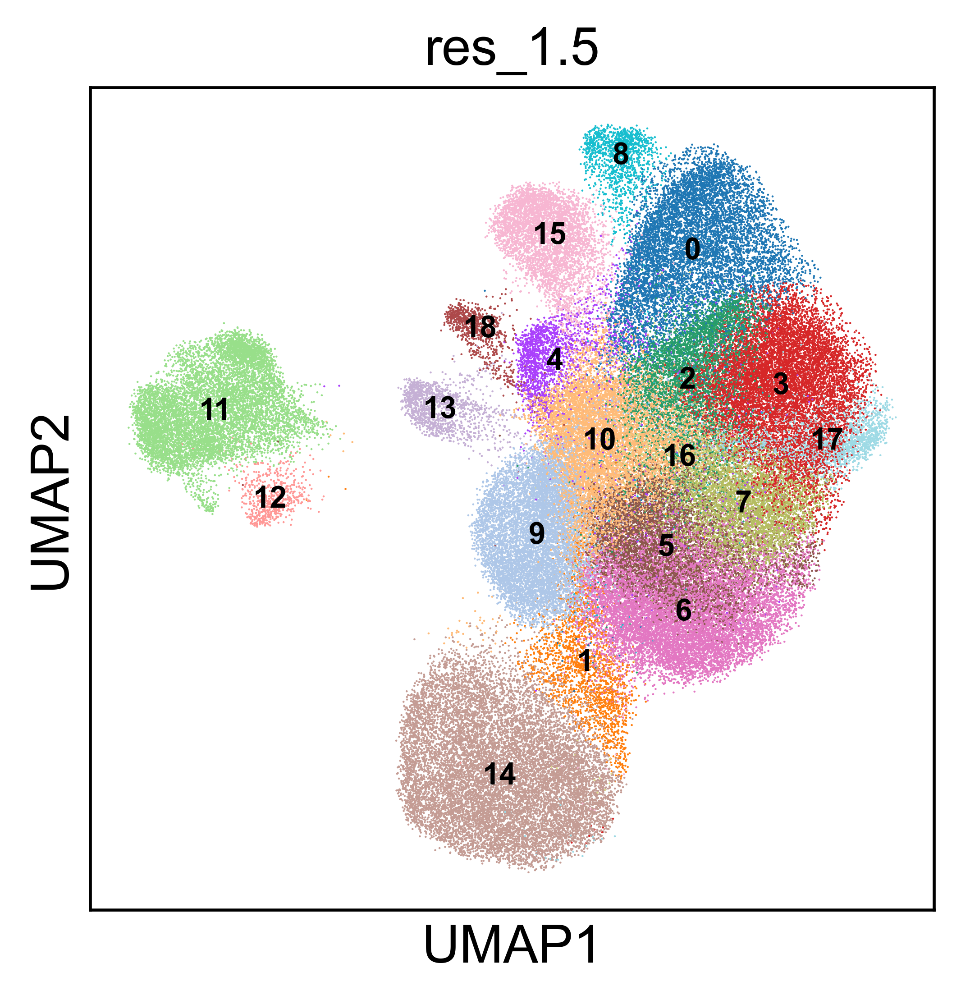

In [6]:
sc.pl.umap(adata,
           color=[f'res_{res}'],
           legend_loc='on data',legend_fontsize='xx-small'
          )

In [7]:
# 클러스터 → annotation 매핑
cluster_to_anno = {
    '0': 'Arterial EC',
    '2': 'Capillary EC', '7': 'Capillary EC', '10': 'Capillary EC',
    '5': 'Venous EC',
    '6': 'Venous iEC',
    '1': 'CCL2+ iEC',
    '14': 'HMOX1+ iEC',
    '11': 'Lymphatic EC', '12': 'Lymphatic EC',
    '8': 'TMEM100+ EC',
    '3': 'Tip EC',
    '17': 'PGF+ Tip EC',
    '15': 'Fibrosis PGF+ Tip EC',
    '13': 'CD14+ EC',
    '18': 'HMGB2+ cycEC',
    '9': 'SPRY1+ EC',
    '16': 'Doublet_Epi',
    '4': 'Doublet_T',
}

annot_ordering = ['Arterial EC', 'Capillary EC', 'Venous EC', 'Venous iEC',
                  'CCL2+ iEC', 'HMOX1+ iEC', 'Lymphatic EC', 'TMEM100+ EC',
                  'Tip EC', 'PGF+ Tip EC', 'Fibrosis PGF+ Tip EC',
                  'CD14+ EC', 'HMGB2+ cycEC', 'SPRY1+ EC',
                  'Doublet_Epi', 'Doublet_T']

adata.obs['res_1.5_str_high_anno'] = adata.obs['res_1.5'].astype(str).map(cluster_to_anno)
adata.obs['res_1.5_str_high_anno_order'] = pd.Categorical(
adata.obs['res_1.5_str_high_anno'], categories=annot_ordering, ordered=True
)

sc.tl.rank_genes_groups(adata, 'res_1.5_str_high_anno_order', method='wilcoxon')

ranking genes


    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:02:02)


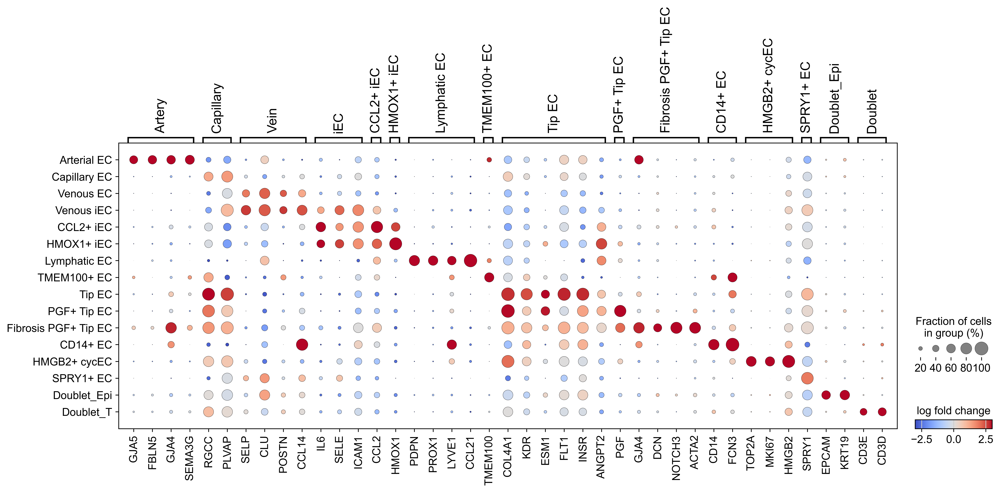

In [8]:
ec_ma={'Artery':['GJA5','FBLN5','GJA4','SEMA3G'],
                   'Capillary':['RGCC','PLVAP'],
                   'Vein':['SELP','CLU','POSTN','CCL14'],
                   'iEC':['IL6','SELE','ICAM1'],
                   'CCL2+ iEC':['CCL2'],
                   'HMOX1+ iEC':['HMOX1'],
                   'Lymphatic EC':['PDPN','PROX1','LYVE1','CCL21'],
                   'TMEM100+ EC':['TMEM100'],
                   'Tip EC':['COL4A1','KDR','ESM1','FLT1','INSR','ANGPT2'],
                   'PGF+ Tip EC':['PGF'],
                   'Fibrosis PGF+ Tip EC':['GJA4','DCN','NOTCH3','ACTA2'],     
                   'CD14+ EC':['CD14','FCN3'], 
                   'HMGB2+ cycEC':['TOP2A','MKI67','HMGB2'],
                   'SPRY1+ EC':['SPRY1'],   
                   'Doublet_Epi':['EPCAM','KRT19'],
                   'Doublet':['CD3E','CD3D'],
                       }

sc.pl.rank_genes_groups_dotplot(adata, 
                                #figsize=(14,7),
                                groupby='res_1.5_str_high_anno_order',
                                values_to_plot='logfoldchanges',
                                vmin=-3,
                                vmax=3,
                                dendrogram=False,
                                var_names=ec_ma,
                                color_map ='coolwarm',
                               )

In [9]:
adata.obs['sub_anno']=adata.obs['res_1.5_str_high_anno'].copy()

In [ ]:
adata=adata[~adata.obs['sub_anno'].isin(['Doublet_Epi','Doublet_T'])]

In [10]:
del adata.obs['res_1.5_str_high_anno_order']
del adata.obs['res_1.5_str_high_anno']
del adata.obs['res_1.5']

In [ ]:
adata.write_h5ad('/path/to/h5ad_annotated/_sc_Endothelial.h5ad')

In [11]:
adata=sc.read_h5ad('/path/to/h5ad_annotated/_sc_Endothelial.h5ad')

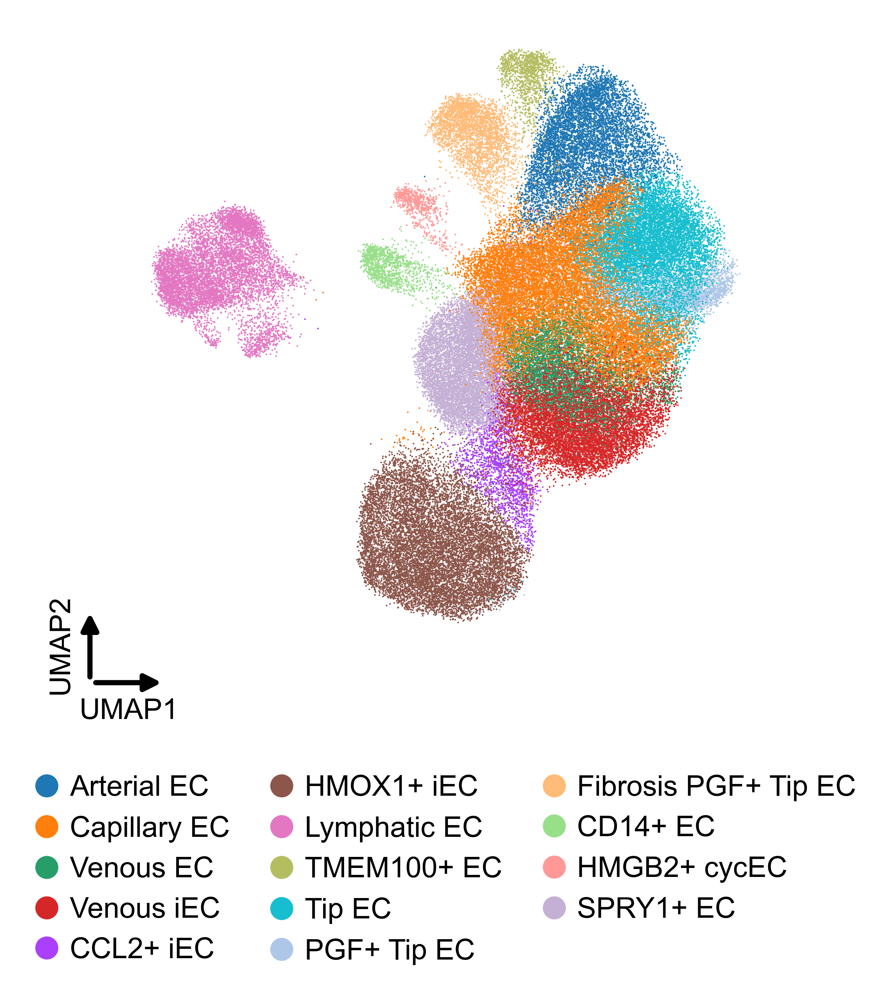

In [12]:
from plotting import umap_with_arrow_axes

umap_with_arrow_axes(adata)

In [13]:
sc.tl.rank_genes_groups(adata,groupby='sub_anno',method='wilcoxon')

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:06:43)


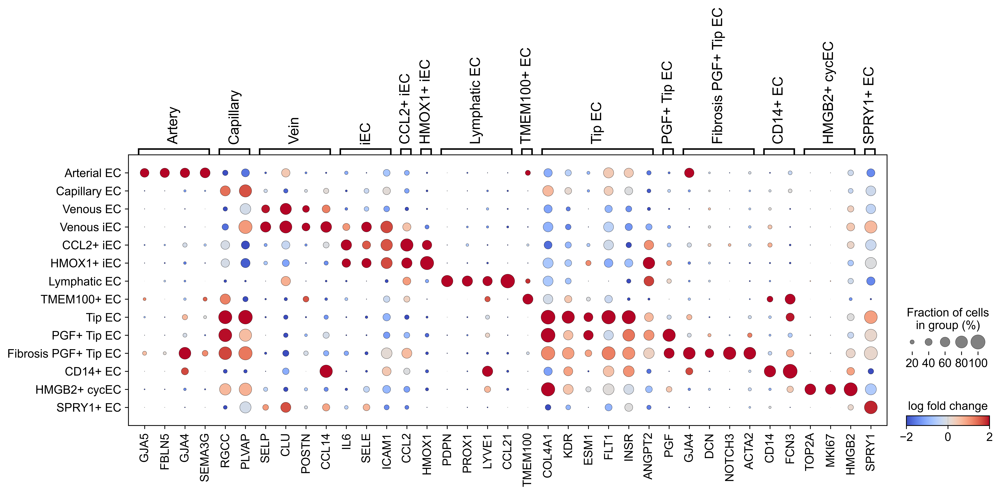

In [14]:
ec_ma= {'Artery':['GJA5','FBLN5','GJA4','SEMA3G'],
                   'Capillary':['RGCC','PLVAP'],
                   'Vein':['SELP','CLU','POSTN','CCL14'],
                   'iEC':['IL6','SELE','ICAM1'],
                   'CCL2+ iEC':['CCL2'],
                   'HMOX1+ iEC':['HMOX1'],
                   'Lymphatic EC':['PDPN','PROX1','LYVE1','CCL21'],
                   'TMEM100+ EC':['TMEM100','HPGD'],
                   'Tip EC':['COL4A1','KDR','ESM1','FLT1','INSR','ANGPT2'],
                   'PGF+ Tip EC':['PGF'],
                   'Fibrosis PGF+ Tip EC':['DCN','NOTCH3','ACTA2'],     
                   'CD14+ EC':['CD14','FCN3'], 
                   'HMGB2+ cycEC':['TOP2A','MKI67','HMGB2'],
                   'SPRY1+ EC':['SPRY1'],     
                       }

sc.pl.rank_genes_groups_dotplot(adata, 
                                groupby='sub_anno',
                                values_to_plot='logfoldchanges',
                                vmin=-2,
                                vmax=2,
                                dendrogram=False,
                                var_names=ec_ma,
                                color_map ='coolwarm',
                               )

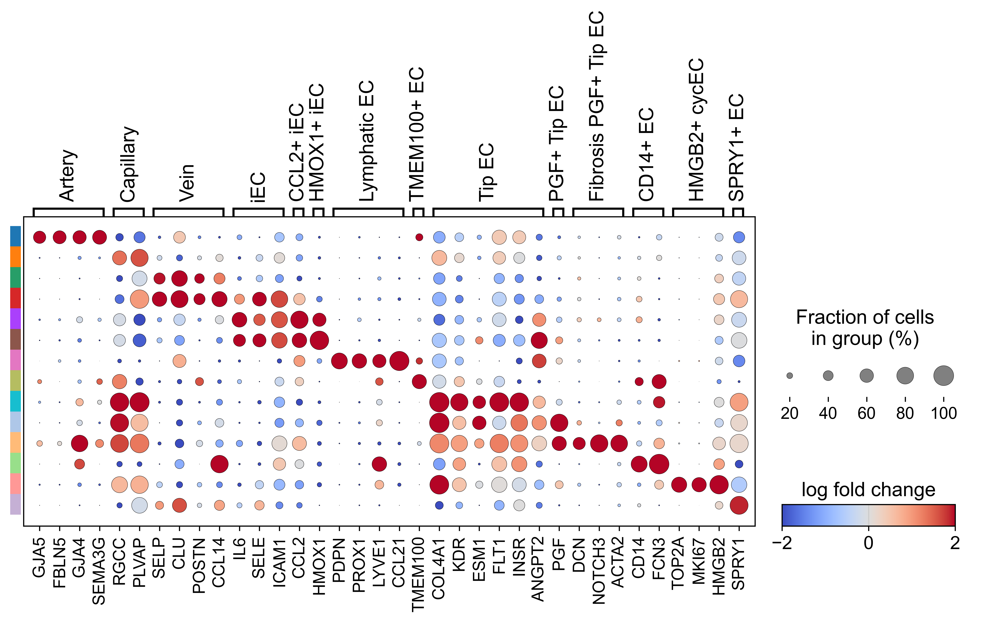

In [15]:
import matplotlib.colors as mcolors

markers = {'Artery':['GJA5','FBLN5','GJA4','SEMA3G'],
                   'Capillary':['RGCC','PLVAP'],
                   'Vein':['SELP','CLU','POSTN','CCL14'],
                   'iEC':['IL6','SELE','ICAM1'],
                   'CCL2+ iEC':['CCL2'],
                   'HMOX1+ iEC':['HMOX1'],
                   'Lymphatic EC':['PDPN','PROX1','LYVE1','CCL21'],
                   'TMEM100+ EC':['TMEM100'],
                   'Tip EC':['COL4A1','KDR','ESM1','FLT1','INSR','ANGPT2'],
                   'PGF+ Tip EC':['PGF'],#'CXCR4','NID2','LXN','ESM1'
                   'Fibrosis PGF+ Tip EC':['DCN','NOTCH3','ACTA2'],     
                   'CD14+ EC':['CD14','FCN3'], 
                   'HMGB2+ cycEC':['TOP2A','MKI67','HMGB2'],
                   'SPRY1+ EC':['SPRY1'],     
                       }

cats = list(adata.obs["sub_anno"].cat.categories)

dp = sc.pl.rank_genes_groups_dotplot(
    adata,
    groupby="sub_anno",
    categories_order=cats,
    var_names=markers,
    #key="Tcell_DEG",
    cmap="coolwarm",
    dendrogram=False,
    values_to_plot="logfoldchanges",
    vmax=2,
    vmin=-2,
    figsize=(11, 4),
    return_fig=True,
    show=False,
)

axes = dp.get_axes()
ax = axes["mainplot_ax"]
fig = ax.figure

# row annotation color bar
color_map = dict(zip(cats, adata.uns["sub_anno_colors"]))
row_colors = [color_map[c] for c in cats]
rgb = np.array([mcolors.to_rgb(c) for c in row_colors]).reshape(len(cats), 1, 3)

ax.set_yticklabels([])
ax.tick_params(axis="y", length=0)

pos = ax.get_position()
bar_ax = fig.add_axes([pos.x0 - 0.012, pos.y0 - 0.023, 0.0095, pos.height])

# 각 block의 중심을 dot row 중심과 맞춤
bar_ax.imshow(
    rgb,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    extent=(0, 1, -0.5, len(cats) - 0.5),
)

bar_ax.set_ylim(ax.get_ylim())
bar_ax.set_xlim(0, 1)
bar_ax.set_xticks([])
bar_ax.set_yticks([])

for spine in bar_ax.spines.values():
    spine.set_visible(False)

# dot size legend 조정
size_ax = axes["size_legend_ax"]
pos2 = size_ax.get_position()
size_ax.set_position([pos2.x0, pos2.y0, pos2.width * 1.8, pos2.height])
size_ax.set_title("Fraction of cells\nin group (%)", x=0.4, y=0.6)

coll = size_ax.collections[0]
offsets = coll.get_offsets()

new_x = np.array([0, 0.5, 1.0, 1.5, 2.0])[:offsets.shape[0]]
offsets[:, 0] = new_x
coll.set_offsets(offsets)

ticklabels = [t.get_text() for t in size_ax.get_xticklabels()]
size_ax.set_xticks(new_x)
size_ax.set_xticklabels(ticklabels)
size_ax.set_xlim(new_x.min() - 0.1, new_x.max() + 0.6)

# colorbar 조정
color_ax = axes["color_legend_ax"]
color_ax.set_title("log fold change", fontsize=14)
color_ax.tick_params(labelsize=13)

pos3 = color_ax.get_position()
color_ax.set_position([pos3.x0, pos3.y0, pos3.width * 1.5, pos3.height])

plt.show()